# Problem

mag.shape torch.Size([1, 128, 128])


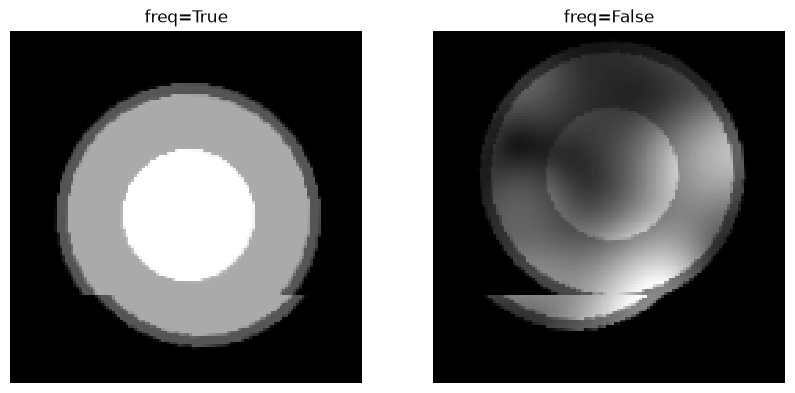

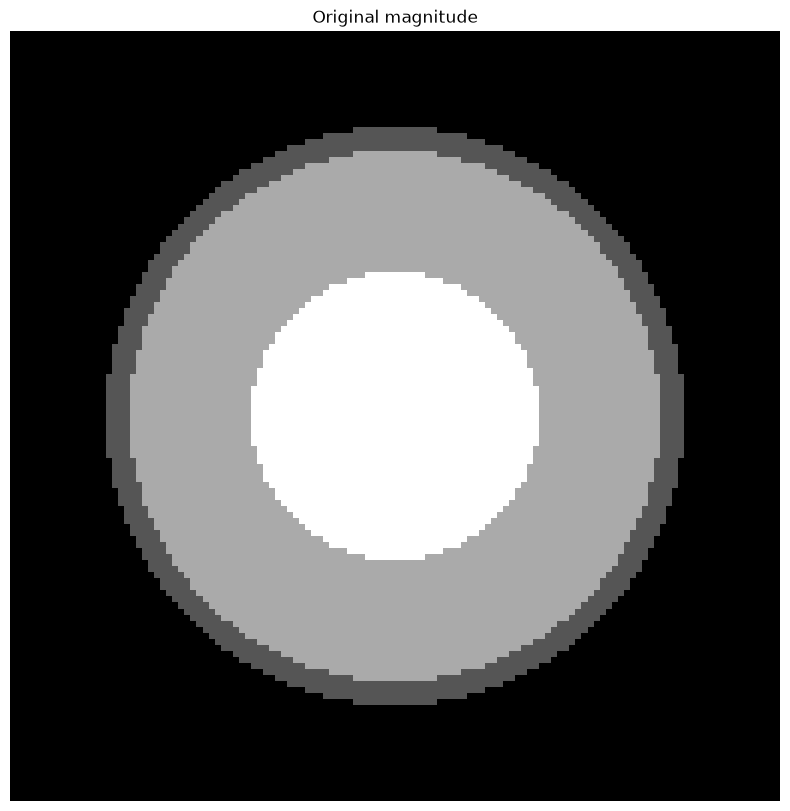

In [23]:
import torch
from cornucopia.utils.py import meshgrid_ij
from cornucopia import (
    IntraScanMotionTransform,
    ArrayCoilTransform,
    SmallIntraScanMotionTransform,
    RandomSlicewiseAffineTransform,
)
import  matplotlib.pyplot as plt

shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

mag = torch.zeros_like(radius, dtype=torch.float32)
mag[radius < 48] = 1
mag[radius < 44] = 2
mag[radius < 24] = 3
# make mag 3D by concatenating along a new dimension
# mag = torch.stack([mag] * 8, dim=-1)  # 8 slices
mag = mag[None]  # channels dimension

print("mag.shape", mag.shape)
# plt.figure(figsize=(10, 10))
# plt.imshow(mag.squeeze(), cmap='gray', interpolation='nearest')
# plt.axis('off')
# plt.title('Signal magnitude')
# plt.colorbar()
# plt.show()

coils=ArrayCoilTransform(ncoils=8)
# trf = IntraScanMotionTransform(coils=coils, freq=True )
trf = IntraScanMotionTransform(shots = 4, translations=0.05, rotations=5.0)
trf2 = IntraScanMotionTransform(coils=coils, freq=False)
sos = trf(mag)
sos2 = trf2(mag)


plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(sos.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('freq=True')
plt.subplot(1, 2, 2)
plt.imshow(sos2.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('freq=False')
plt.show()

# plot iriginal mag
plt.figure(figsize=(10, 10))
plt.imshow(mag.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Original magnitude') 
plt.show()

# Using local librarie

In [18]:
import sys
sys.path.append('/home/agustin/phd/local_preprocessing/augmentation')

import torch
from local_cornucopia.cornucopia.utils.py import meshgrid_ij
from local_cornucopia.cornucopia import (
    IntraScanMotionTransform,
    ArrayCoilTransform,
    SmallIntraScanMotionTransform,
    RandomSlicewiseAffineTransform,
)
import  matplotlib.pyplot as plt

In [19]:
def show_image(img, seg, title=None):
    plt.figure(figsize=(10, 10))
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
    plt.title('MRI')
    plt.subplot(1, 2, 2)
    plt.imshow(seg.squeeze(), cmap='tab20', interpolation='nearest')
    plt.axis('off')
    plt.title('Labels')
    plt.show()

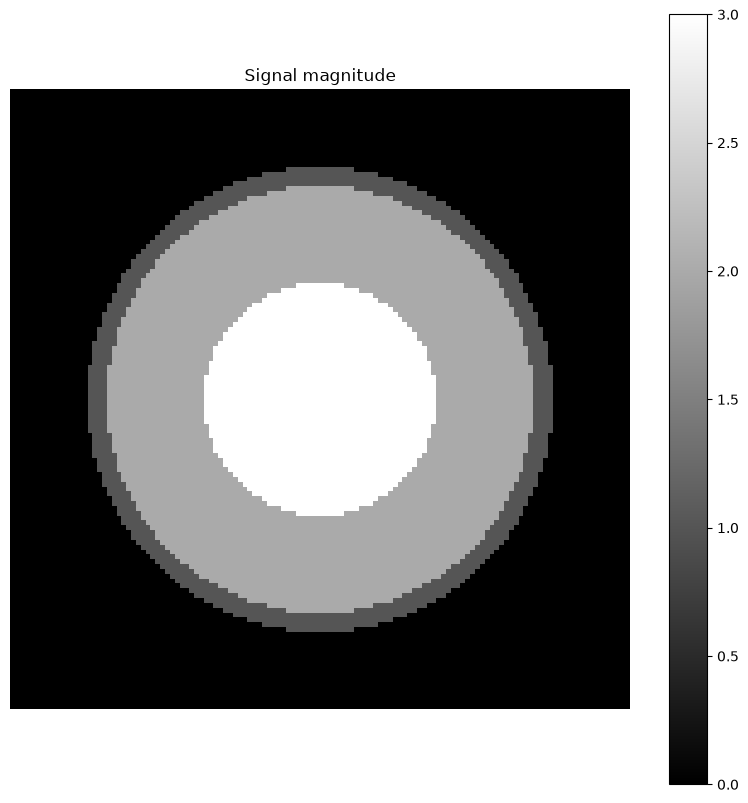

In [20]:
shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

mag = torch.zeros_like(radius, dtype=torch.float32)
mag[radius < 48] = 1
mag[radius < 44] = 2
mag[radius < 24] = 3
mag = mag[None]  # channels dimension

plt.figure(figsize=(10, 10))
plt.imshow(mag.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Signal magnitude')
plt.colorbar()
plt.show()

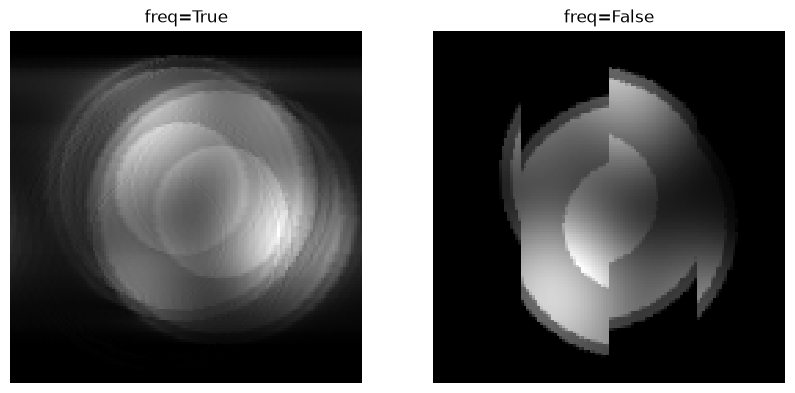

In [21]:
# coils=ArrayCoilTransform(ncoils=8, fwhm=0.5, diameter=0.8, jitter=0.01, unit='fov', shape=4, sos=True,)
coils=ArrayCoilTransform(ncoils=8)
trf = IntraScanMotionTransform(coils=coils, freq=True)
trf2 = IntraScanMotionTransform(coils=coils, freq=False)
sos = trf(mag)
sos2 = trf2(mag)


plt.figure(figsize=(10, 10))
plt.subplot(1, 2, 1)
plt.imshow(sos.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('freq=True')
plt.subplot(1, 2, 2)
plt.imshow(sos2.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('freq=False')
plt.show()

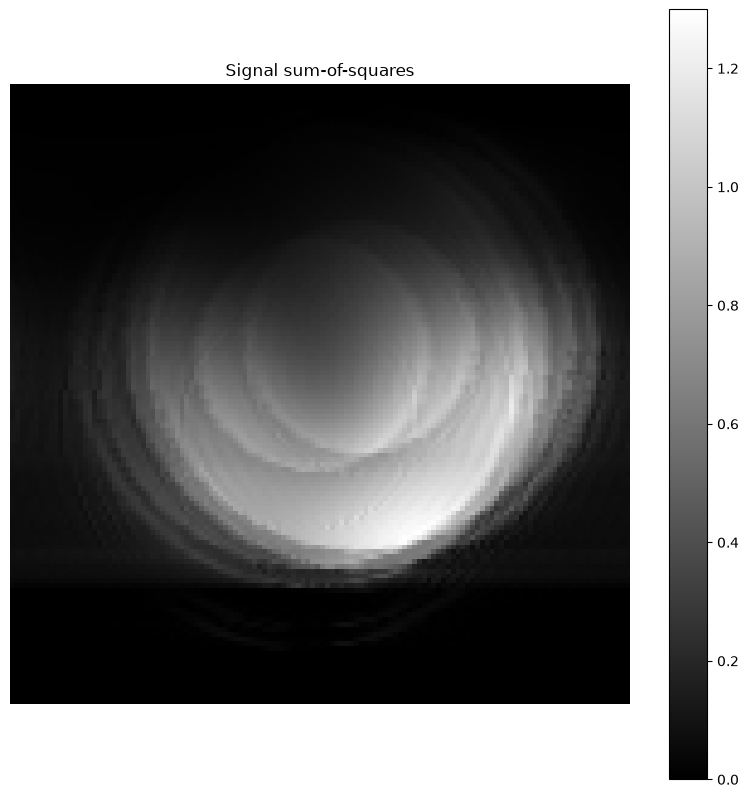

In [11]:
trf = IntraScanMotionTransform(coils=ArrayCoilTransform())
sos = trf(mag)

plt.figure(figsize=(10, 10))
plt.imshow(sos.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Signal sum-of-squares')
plt.colorbar()
plt.show()

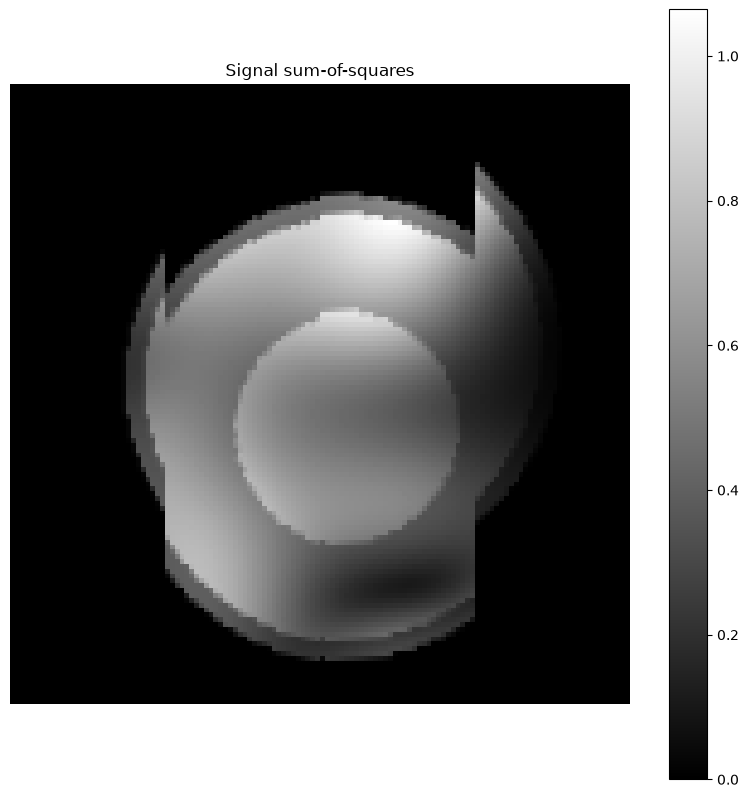

In [12]:
plt.show()
trf = IntraScanMotionTransform(coils=ArrayCoilTransform(), freq=False)
sos = trf(mag)

plt.figure(figsize=(10, 10))
plt.imshow(sos.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Signal sum-of-squares')
plt.colorbar()
plt.show()

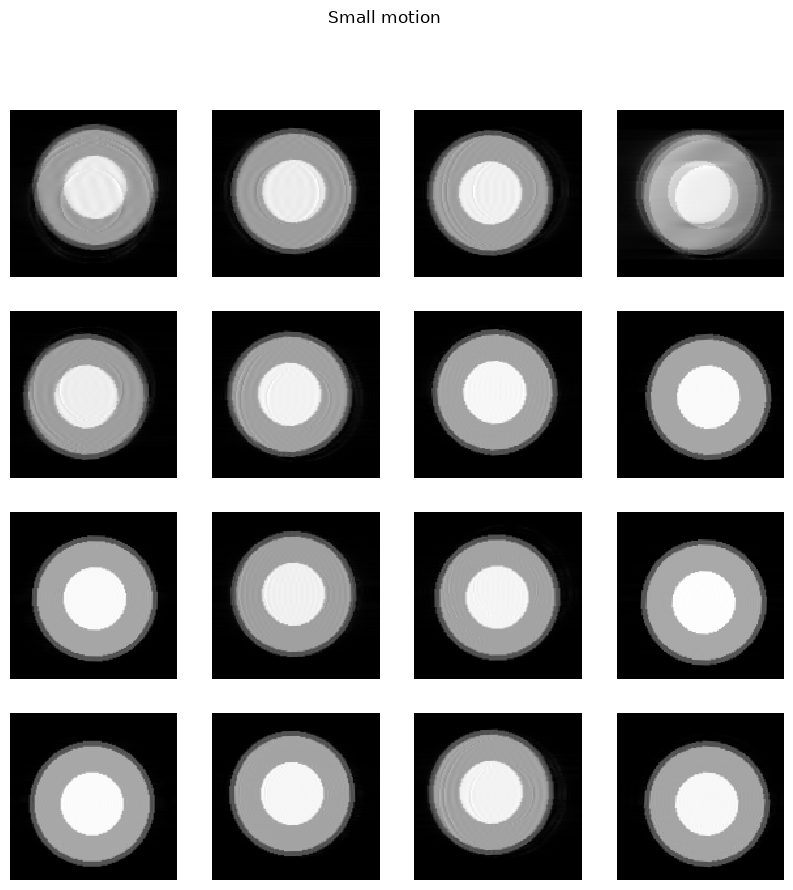

In [13]:
trf = SmallIntraScanMotionTransform()

shape = [4, 4]
plt.rcParams["figure.figsize"] = (15, 15)

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    plt.imshow(trf(mag).squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Small motion')
plt.show()

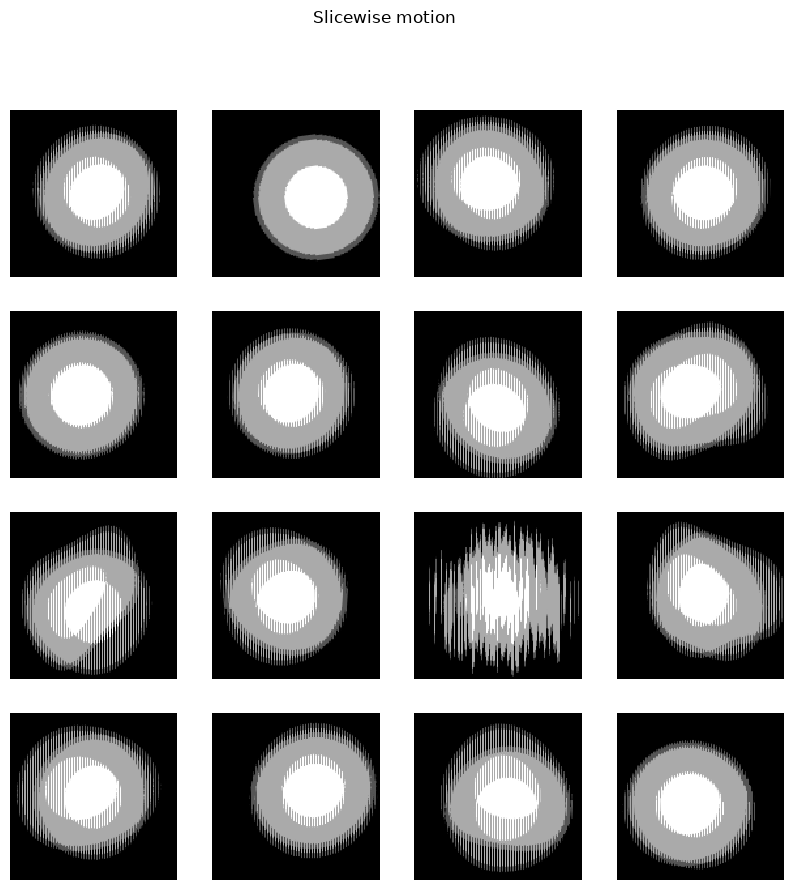

In [14]:
trf = RandomSlicewiseAffineTransform()

shape = [4, 4]
plt.rcParams["figure.figsize"] = (15, 15)

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    plt.imshow(trf(mag).squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Slicewise motion')
plt.show()

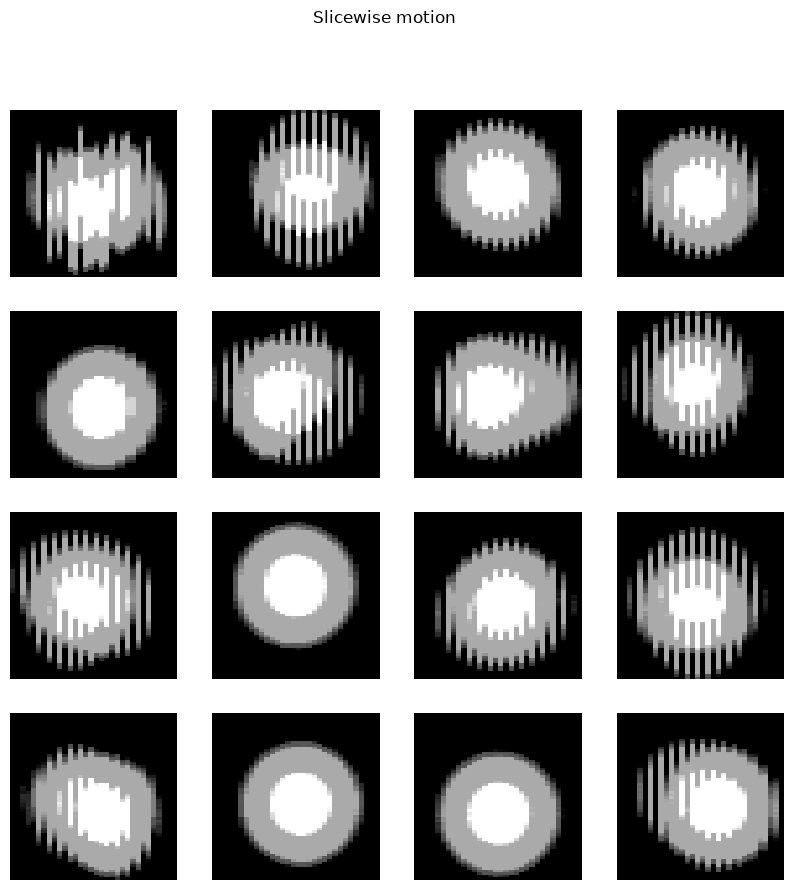

In [15]:
trf = RandomSlicewiseAffineTransform(spacing=4, subsample=2)

shape = [4, 4]
plt.rcParams["figure.figsize"] = (15, 15)

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    plt.imshow(trf(mag).squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Slicewise motion')
plt.show()

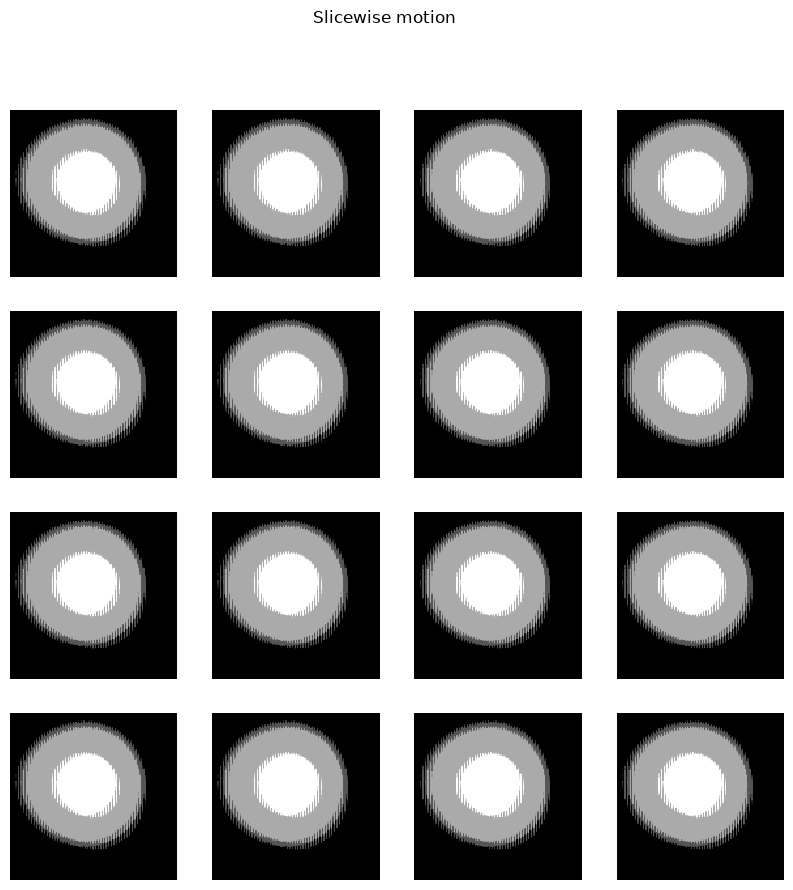

In [16]:
# It is also possible to provide pre-computed motion trajectories 
# that get interpolated with cubic splines

from cornucopia.random import Fixed
rotations = Fixed(torch.rand([5, 1])*15)
translations = Fixed(torch.rand([5, 2])*0.1)
trf = RandomSlicewiseAffineTransform(
    rotations=rotations, translations=translations,
    bulk_translations=0, bulk_rotations=0,
)

shape = [4, 4]
plt.rcParams["figure.figsize"] = (15, 15)

plt.figure(figsize=(10, 10))
for i in range(shape[0] * shape[1]):
    plt.subplot(*shape, i+1)
    plt.imshow(trf(mag).squeeze(), cmap='gray', interpolation='nearest')
    plt.axis('off')
plt.suptitle('Slicewise motion')
plt.show()